# Solar filament instance segmentation: the whole pipeline

This notebook runs every step of our solution to the *Filament Segmentation 2026* challenge and reproduces the
submitted predictions from the weights stored in this repository, without retraining:

1. data and evaluation protocol
2. preprocessing (limb fit, flat-field)
3. models and training (optional: the shipped weights are used unless `RETRAIN = True`)
4. inference on the test frames
5. post-processing and the submission file, compared with the submitted one
6. evaluation on the training set, out-of-fold

**Requirements.** One CUDA GPU with 8 GB or more, the packages of `requirements.txt` (or the image in `docker/`),
and the competition data unpacked to `data/MAGFiLO_1.0_Kaggle_2026/`. Sections 2, 4 and 5 take about 40 minutes
on an idle RTX 4090 and 20 GB of cache. Section 6 adds about 38 minutes and 40 GB of cache; set `RUN_OOF = False` to skip it.
The outputs stored in this notebook come from a run whose section 4 shared the GPU with another job, so the run-time
table at the end shows a longer inference time than on an idle GPU.

The code lives in `src/`; the notebook only calls it and shows intermediate results. Every module starts with a
description of what it does and how to run it.

In [1]:
import os, sys, json, time, subprocess, numpy as np
ROOT = os.path.abspath("."); sys.path.insert(0, f"{ROOT}/src/fb")
import matplotlib; matplotlib.rcParams["figure.dpi"] = 110
import torch
from data import DATA, CACHE, RUNS, load_sets
import viz

RETRAIN = False    # True: train all 20 networks from scratch (about 15 GPU-hours on an RTX 4090, 27 GB of cache)
RUN_OOF = True     # False: skip section 6 (out-of-fold evaluation on the training set)

FOLDS = range(5)
R34 = [f"unet_r34_f{k}" for k in FOLDS]      # U-Net, ResNet-34 encoder       } target = mean of all annotator
EFF = [f"unet_effv2s_f{k}" for k in FOLDS]    # U-Net, EfficientNetV2-S encoder } records (soft label in [0, 1])
PVT = [f"unet_pvtv2_f{k}" for k in FOLDS]     # U-Net, PVTv2-B2 encoder         }
UNETS = {"r34": R34, "eff": EFF, "pvt": PVT}
DET = [f"maskrcnn_f{k}" for k in FOLDS]       # Mask R-CNN on three classical-filter channels
TIMES = {}

def sh(cmd, tail=1500):
    """Run one pipeline command, show the end of its output, stop on failure."""
    print("$", cmd, flush=True)
    p = subprocess.run(cmd, shell=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    print(p.stdout[-tail:], flush=True); assert p.returncode == 0, f"command failed: {cmd}"

assert os.path.isdir(f"{DATA}/test/test_images"), f"competition data not found in {DATA}"
print("data   ", DATA); print("cache  ", CACHE); print("weights", RUNS)
print("torch", torch.__version__, "|", torch.cuda.get_device_name(0))

data    /work/data/MAGFiLO_1.0_Kaggle_2026
cache   /cache
weights /work/weights
torch 2.6.0+cu124 | NVIDIA GeForce RTX 4090


## 1. Data and evaluation protocol

The training set has 707 H-alpha frames (2048 x 2048, 8 bit) with 8199 annotated filaments in 1154 annotator
records: a frame was annotated independently by one, two or three people, and the host scores a prediction
against **every** record of the frame (Panoptic Quality, a match needs IoU > 0.5, statistics pooled over all records).

The records of one frame differ. Below: the same window of one frame as marked by three annotators. They agree on
the large dark filaments and disagree on which small ones to mark and on where one filament ends and the next begins.
A copy of one annotator scores PQ 0.33 against another annotator of the same frame (151 frames with three records).
This sets the scale for every number below, and it is why our three U-Net families are trained on the *mean* of
the records rather than on one of them.

707 frames, 1154 annotator records, 8199 filaments
records per frame: {1: 411, 2: 145, 3: 151}


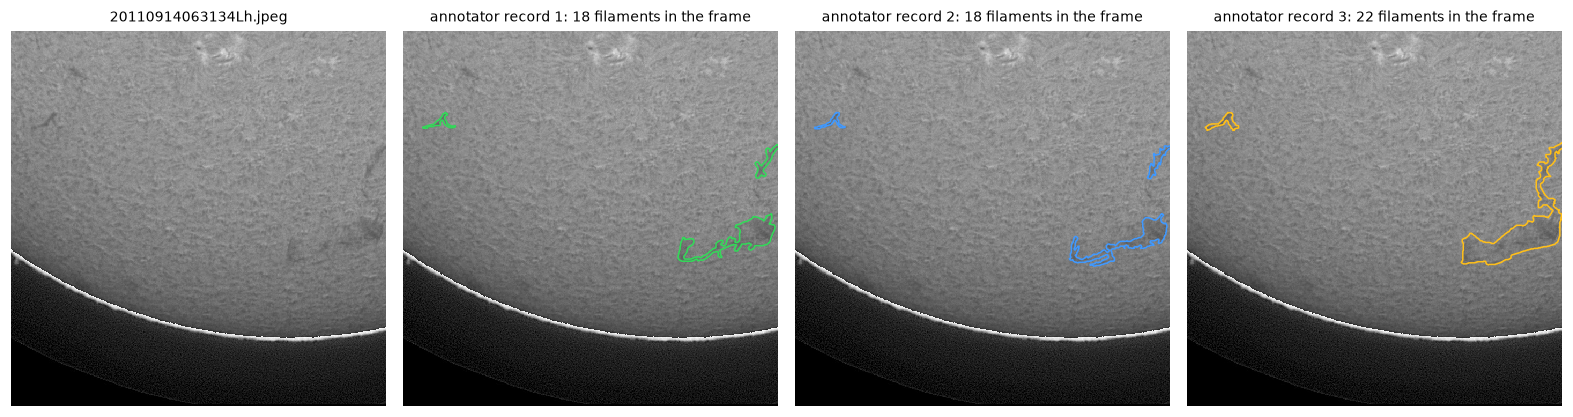

In [2]:
sets = load_sets()
print(f"{len(sets)} frames, {sum(len(v) for v in sets.values())} annotator records, {sum(len(s) for v in sets.values() for s in v)} filaments")
print("records per frame:", {k: sum(len(v) == k for v in sets.values()) for k in (1, 2, 3)})
name3 = max((n for n in sets if len(sets[n]) == 3), key=lambda n: sum(len(s) for s in sets[n]))
viz.annotators(name3);

## 2. Preprocessing

`src/fb/disk.py`, `src/fb/data.py`. For every frame:

1. **Limb fit.** The limb is the steepest radial intensity drop along 720 rays; a robust least-squares circle gives centre and radius.
2. **Flat-field.** The frame is divided by the radial median centre-to-limb profile (removes limb darkening), then
   scaled by a robust z-score inside the disk. Quiet Sun becomes approximately N(0, 1), off-disk pixels are exactly 0.

The result is cached as float16. Nothing else is done to the image: the networks work on the native 2048 x 2048 grid,
because a median filament is only about 11 px wide and one pixel of width changes its IoU by several points.

$ python src/fb/data.py test


test 180 frames cached; disk fit mean [1023.01 1024.1   903.85] std [0.44 0.47 0.97]



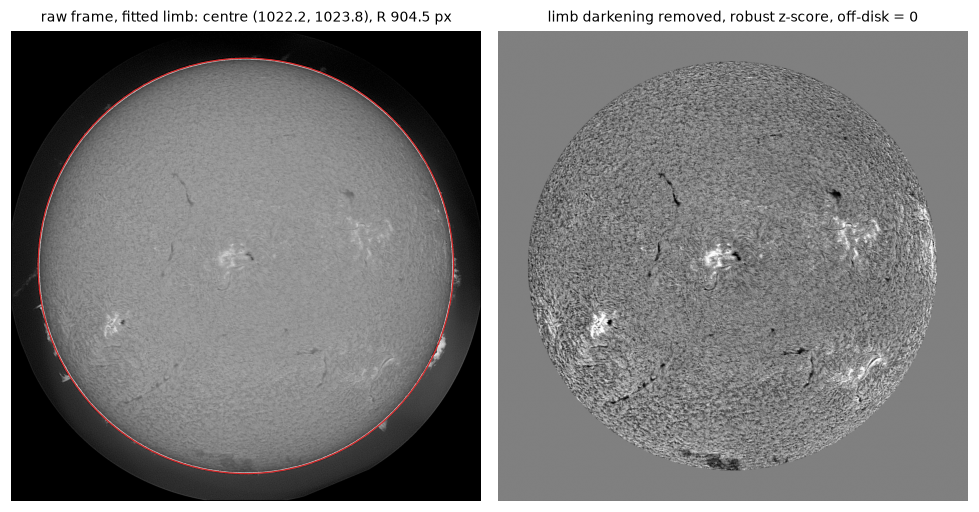

In [3]:
t0 = time.time()
sh("python src/fb/data.py test")
TIMES["preprocessing, test frames"] = time.time() - t0
test_names = json.load(open(f"{CACHE}/test_meta.json"))["names"]
viz.preprocessing(test_names[40], "test");

## 3. Models and training

Four families, five folds each (the 707 frames are split by file into five blocks; model `f<k>` never saw block `k`).

| Family | Network | Input | Target | Training |
|---|---|---|---|---|
| `unet_r34` | U-Net, ResNet-34 encoder (ImageNet init), 24.4 M parameters | flat-fielded frame, 1 channel | mean of all annotator records (soft label in [0, 1]) | 18 000 steps, crops 768 + 128 px context, batch 8, AdamW lr 5e-4, BCE + Dice, EMA weights |
| `unet_effv2s` | U-Net, EfficientNetV2-S encoder (ImageNet init) | same | same | same, lr 3e-4 |
| `unet_pvtv2` | U-Net, PVTv2-B2 encoder (ImageNet init), a vision transformer | same | same | same, lr 3e-4, encoder at 0.3 x lr |
| `maskrcnn` | Mask R-CNN, ResNet-50 FPN v2 (COCO init), anchors 16-256 px | 3 channels: flat frame, starlet band-pass, Hessian dark-ridge | instances of the fullest record | 6 000 iterations, crops 1024, batch 2, SGD |

The three U-Net families differ only in the encoder. An average of five models with one encoder gains little from more
models of the same kind; models with different encoders make different mistakes, and the transformer encoder
(PVTv2) differs most from the two convolutional ones. On out-of-fold data one encoder gives PQ 0.452, two 0.460,
three 0.464.

Augmentation (`src/fb/augment.py`): the eight flips / rotations, free rotation and zoom, gain and offset, tone curve,
seeing blur, veil, noise. Mask R-CNN output is turned into a map `max_n(score_n * mask_n)`, so all three families
produce a per-pixel map and can be averaged.

Training is optional here. With `RETRAIN = False` the weights in `weights/` are used (stored as float16, cast to
float32 on load).

In [4]:
if RETRAIN:
    sh("python src/fb/data.py")                               # train + test frames and all training targets
    sh("python src/det/maskrcnn.py prep")                     # three-channel composites for Mask R-CNN
    for k in FOLDS:
        common = f"--fold {k} --aug strong --target tsoftc --steps 18000"
        sh(f"python src/fb/train.py --name unet_r34_f{k} {common}")
        sh(f"python src/fb/train.py --name unet_effv2s_f{k} {common} --enc tu-tf_efficientnetv2_s --lr 3e-4")
        sh(f"python src/fb/train.py --name unet_pvtv2_f{k} {common} --enc tu-pvt_v2_b2 --lr 3e-4 --enc_lr_k 0.3")
        sh(f"python src/det/maskrcnn.py train --name maskrcnn_f{k} --fold {k}")
else:
    for r in R34 + EFF + PVT + DET:
        f = f"{RUNS}/{r}/" + ("model.pt" if r.startswith("maskrcnn") else "ema.pt"); assert os.path.exists(f), f
    print("using the shipped weights:", ", ".join(R34 + EFF + PVT + DET))

using the shipped weights: unet_r34_f0, unet_r34_f1, unet_r34_f2, unet_r34_f3, unet_r34_f4, unet_effv2s_f0, unet_effv2s_f1, unet_effv2s_f2, unet_effv2s_f3, unet_effv2s_f4, unet_pvtv2_f0, unet_pvtv2_f1, unet_pvtv2_f2, unet_pvtv2_f3, unet_pvtv2_f4, maskrcnn_f0, maskrcnn_f1, maskrcnn_f2, maskrcnn_f3, maskrcnn_f4


## 4. Inference on the test frames

`src/fb/infer.py`, `src/det/maskrcnn.py`. Full 2048 x 2048 frames, no tiling and no resizing.

- U-Net families: the five fold models and the eight flips / rotations are averaged (40 passes per frame and family).
- Mask R-CNN: horizontal-flip test-time augmentation, then the plain average of the five fold models.
- In addition every single model is run once with horizontal flip only. These maps are not part of the prediction;
  the post-processing uses them to transfer its thresholds to the ensemble (section 5).

In [5]:
t0 = time.time()
for fam, runs in UNETS.items():
    for k in FOLDS:
        sh(f"python src/fb/infer.py --runs {runs[k]} --tta hflip --tag {fam}_f{k}_h", 300)
    sh(f"python src/fb/infer.py --runs {','.join(runs)} --tta d4 --tag {fam}_5", 300)
TIMES["inference, 15 U-Nets"] = time.time() - t0; t0 = time.time()
sh("python src/det/maskrcnn.py prep --only test", 300)
for r in DET: sh(f"python src/det/maskrcnn.py test --name {r}", 300)
TIMES["inference, 5 Mask R-CNN"] = time.time() - t0

$ python src/fb/infer.py --runs unet_r34_f0 --tta hflip --tag r34_f0_h


180 frames, 1 models x 2 views: 149 ms/frame -> /cache/pred/r34_f0_h_test.npy



$ python src/fb/infer.py --runs unet_r34_f1 --tta hflip --tag r34_f1_h


180 frames, 1 models x 2 views: 146 ms/frame -> /cache/pred/r34_f1_h_test.npy



$ python src/fb/infer.py --runs unet_r34_f2 --tta hflip --tag r34_f2_h


180 frames, 1 models x 2 views: 147 ms/frame -> /cache/pred/r34_f2_h_test.npy



... (38 outputs left out)

$ python src/det/maskrcnn.py test --name maskrcnn_f3


test predicted



$ python src/det/maskrcnn.py test --name maskrcnn_f4


test predicted



## 5. Post-processing and the submission file

`src/fb/pq.py`, `src/fb/submit.py`, rule in `rules/final.json` (fitted on out-of-fold maps by `src/fb/oof.py rule`).

1. **Blend.** Weighted average of the four family maps: 0.233 each U-Net family, 0.30 `maskrcnn`.
2. **Objects.** 8-connected components of `prob > 0.2`.
3. **Keep or drop.** An object is kept when its mean probability and area pass thresholds that depend on the distance
   of its centroid from disk centre (three rings: r/R < 0.8, 0.8-0.9, > 0.9). Annotators mark far fewer filaments near
   the limb, and every extra object costs half a point in the PQ denominator for every annotator record.
4. **Trim.** The kept object is cut to its pixels with `prob > 0.5`: the component defines the object, the more
   confident core defines its outline.
5. **One piece.** Trimming breaks some objects into pieces, while an annotated filament is one piece without holes.
   Holes are filled, islands under 5% of the object are removed, and remaining pieces are connected along the
   cheapest path through the probability map.
6. **Calibration (no labels).** The thresholds were fitted on maps of single models. An average of many models has a
   different probability scale, so the thresholds are shifted until the ensemble keeps as many objects, with the
   same area, as the unchanged rule keeps on the single-model maps of the same test frames.

The file is then re-read from disk and validated (ids, RLE size, no empty and no overlapping masks) and compared with
the file we submitted to Kaggle (`submission/submission.csv`).

In [6]:
t0 = time.time()
single = ";".join([",".join(f"{fam}_f{k}_h" for k in FOLDS) for fam in UNETS] + [",".join(DET)])
sh(f'python src/fb/submit.py --rule rules/final.json --ens r34_5,eff_5,pvt_5,{"+".join(DET)} --single "{single}" '
   f'--out submission/reproduced.csv --ref submission/submission.csv', 3000)
TIMES["post-processing and CSV"] = time.time() - t0

$ python src/fb/submit.py --rule rules/final.json --ens r34_5,eff_5,pvt_5,maskrcnn_f0+maskrcnn_f1+maskrcnn_f2+maskrcnn_f3+maskrcnn_f4 --single "r34_f0_h,r34_f1_h,r34_f2_h,r34_f3_h,r34_f4_h;eff_f0_h,eff_f1_h,eff_f2_h,eff_f3_h,eff_f4_h;pvt_f0_h,pvt_f1_h,pvt_f2_h,pvt_f3_h,pvt_f4_h;maskrcnn_f0,maskrcnn_f1,maskrcnn_f2,maskrcnn_f3,maskrcnn_f4" --out submission/reproduced.csv --ref submission/submission.csv


single-model blends, rule as is: [6.48/frame, 2010 px]  [6.38/frame, 2038 px]  [6.62/frame, 2014 px]  [6.65/frame, 2029 px]  [6.64/frame, 1978 px]
calibration (paired): the unchanged rule would keep 6.47 objects/frame of 2034 px; target 6.56 of 2014 px -> mean thresholds shifted by -0.009, inner 0.5 -> 0.505
VALID submission/reproduced.csv: 1179 instances on 177/180 frames; per frame median 6 mean 6.5 max 16; area p5/p50/p95 [ 375. 1301. 6215.]
agreement of submission/reproduced.csv with submission/submission.csv: PQ 0.9991; matched 1178 of 1179 / 1178 masks



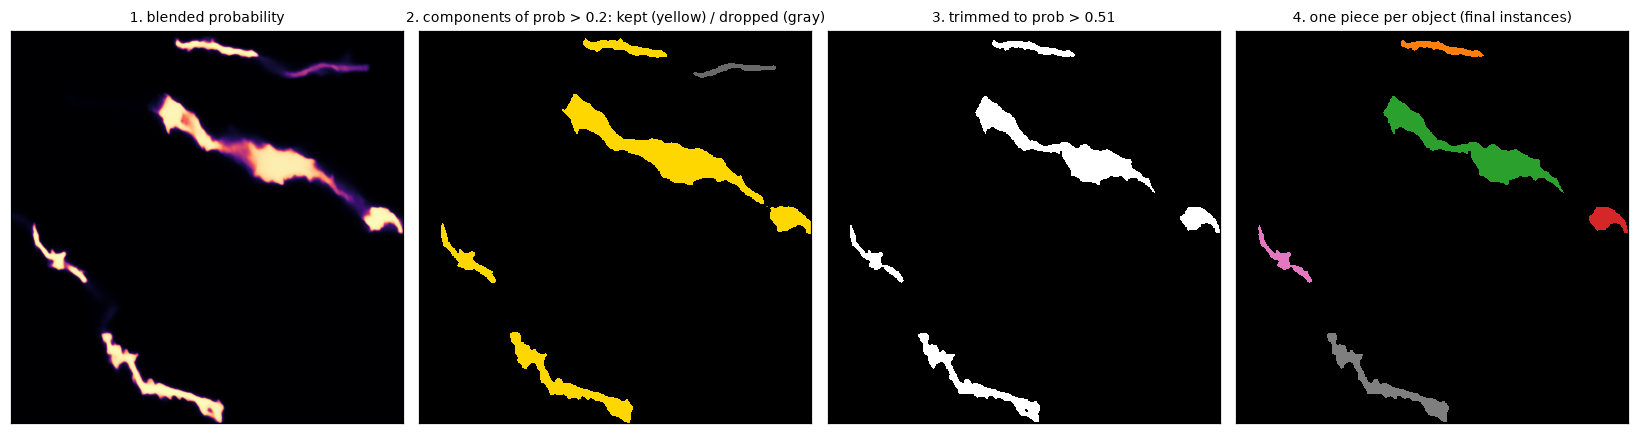

In [7]:
import pq as PQ
applied = json.load(open("submission/reproduced.rule.json"))["applied"]       # the rule after calibration
fam = [["r34_5"], ["eff_5"], ["pvt_5"], DET]
def blended(i):
    """Blended probability map of test frame i, as submit.py builds it."""
    maps = [np.mean([np.load(f"{CACHE}/pred/{t}_test.npy", mmap_mode="r")[i] for t in tags], 0) for tags in fam]
    return (sum(w * m for w, m in zip(applied["weights"], maps)) / (255 * sum(applied["weights"]))).astype(np.float32)

sub = viz.read_submission("submission/reproduced.csv")
i = max(range(len(test_names)), key=lambda j: len(sub.get(test_names[j].rsplit(".", 1)[0], [])))     # the busiest test frame
stem = test_names[i].rsplit(".", 1)[0]; prob = blended(i)
viz.pipeline_steps(prob, applied, viz.busiest_box(sub[stem], 700));

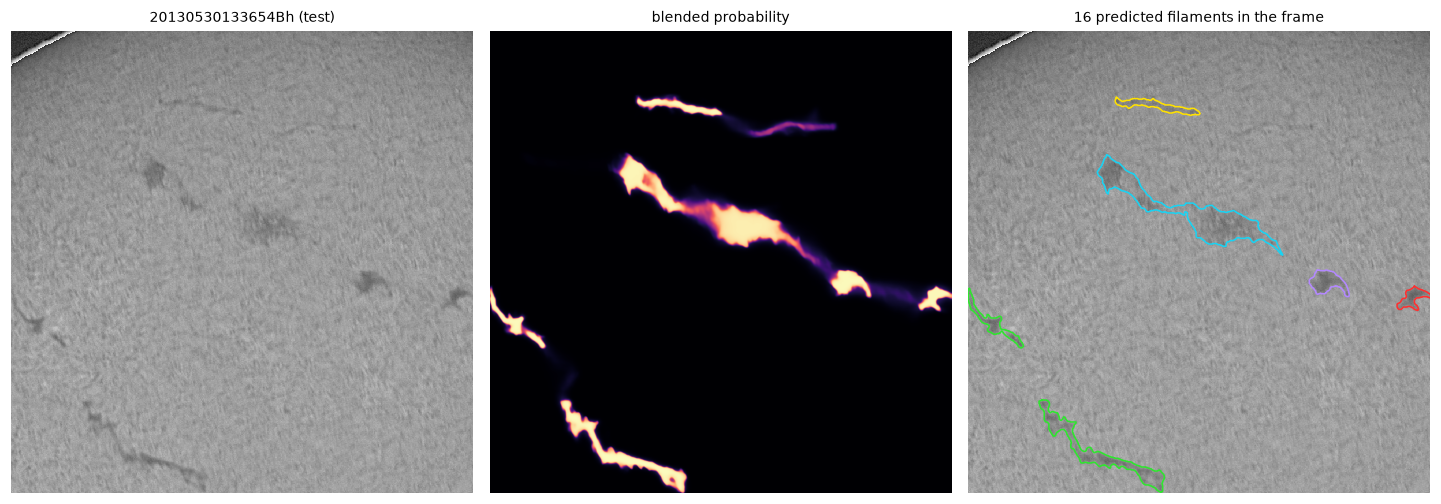

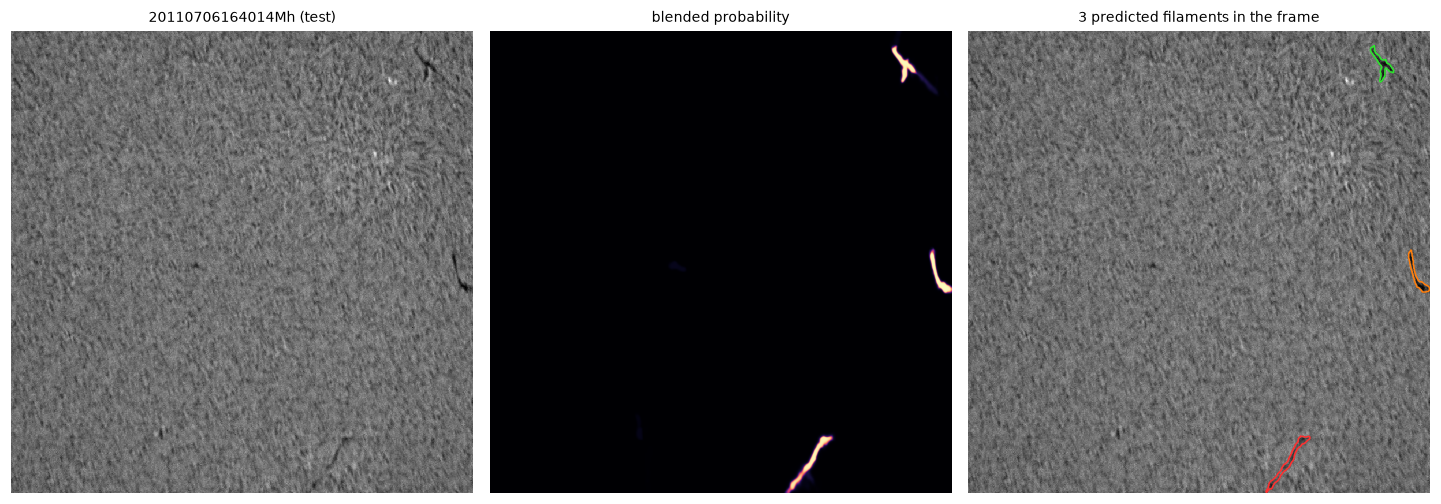

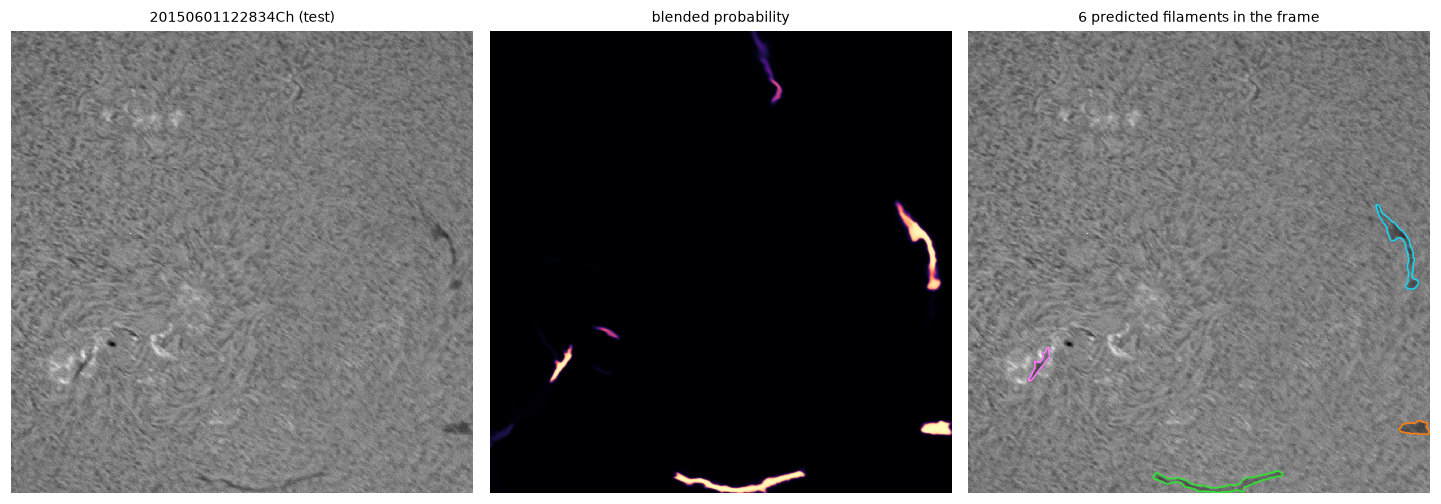

In [8]:
viz.prediction(stem, sub, prob);
for j in (10, 95):
    viz.prediction(test_names[j].rsplit(".", 1)[0], sub, blended(j));

## 6. Evaluation on the training set (out-of-fold)

Every training frame is predicted by the fold model that never saw it, the maps of the five folds are put together,
and the same post-processing function that writes the submission (`pq.instances`) builds the objects. They are scored
exactly like the host does. Nothing is retrained: the held-out frames are re-predicted from the shipped weights.

`src/fb/evaluate.py` also prints what the jury rubric lists next to PQ: the distributions of IoU and Dice over the
ground-truth segments, and the one-to-many / many-to-one relations (a predicted and a ground-truth segment are
related when the smaller one lies at least half inside the other). Its last lines measure annotator agreement on
the 151 frames with three records: one annotator scored against another, and our prediction against the same records.

$ python src/fb/data.py train:flat


train 707 frames cached; disk fit mean [1023.02 1024.06  903.9 ] std [0.44 0.45 0.9 ]



$ python src/fb/infer.py --runs unet_r34_f0 --split val --fold 0 --tta hflip --tag oof


141 frames, 1 models x 2 views: 69 ms/frame -> /cache/runs/unet_r34_f0/val_probs.npy



$ python src/fb/infer.py --runs unet_r34_f1 --split val --fold 1 --tta hflip --tag oof


141 frames, 1 models x 2 views: 81 ms/frame -> /cache/runs/unet_r34_f1/val_probs.npy



... (44 outputs left out)

$ python src/fb/oof.py assemble --tag maskrcnn --runs maskrcnn_f0,maskrcnn_f1,maskrcnn_f2,maskrcnn_f3,maskrcnn_f4


/cache/oof/maskrcnn.npy: 707 frames from ['maskrcnn_f0', 'maskrcnn_f1', 'maskrcnn_f2', 'maskrcnn_f3', 'maskrcnn_f4']



$ python src/fb/evaluate.py rules/final.json figures/oof_eval.npz


rule rules/final.json (one_piece = 2), 707 out-of-fold frames, 1154 annotator records
PQ 0.4640 = SQ 0.6855 x RQ 0.6769;  TP 5335  FP 2230  FN 2864
per fold: 0.4608  0.4786  0.4583  0.4588  0.4635
predicted objects 4606 (6.51 per frame); with 2+ pieces: 0.0%
best IoU of every ground-truth segment (8199): none 19.0% | 0.0-0.1: 0.4%  0.1-0.2: 1.6%  0.2-0.3: 3.1%  0.3-0.4: 4.4%  0.4-0.5: 6.3%  0.5-0.6: 12.5%  0.6-0.7: 22.1%  0.7-0.8: 24.7%  0.8-0.9: 5.7%  0.9-1.0: 0.0% | mean 0.501, median 0.615, mean over matched 0.686
best Dice of every ground-truth segment (8199): none 19.0% | 0.0-0.1: 0.1%  0.1-0.2: 0.5%  0.2-0.3: 1.1%  0.3-0.4: 1.8%  0.4-0.5: 3.1%  0.5-0.6: 4.5%  0.6-0.7: 8.6%  0.7-0.8: 22.3%  0.8-0.9: 35.8%  0.9-1.0: 3.2% | mean 0.607, median 0.762, mean over matched 0.810
one-to-many (a ground-truth segment related to 2+ predictions): 180 of 8199 ground-truth segments (2.2%)
many-to-one (a prediction related to 2+ ground-truth segments of one record): 258 of 7564 prediction x recor

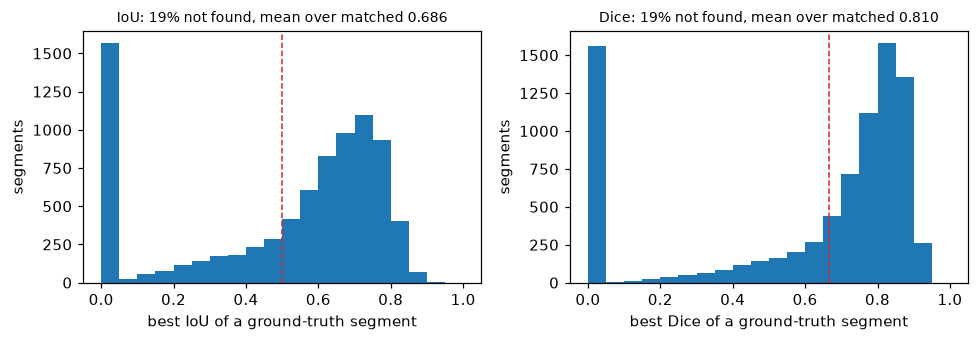

In [9]:
if RUN_OOF:
    t0 = time.time()
    sh("python src/fb/data.py train:flat", 300)
    for runs in UNETS.values():
        for k in FOLDS:
            sh(f"python src/fb/infer.py --runs {runs[k]} --split val --fold {k} --tta hflip --tag oof", 300)
    sh("python src/det/maskrcnn.py prep --only train", 300)
    for k in FOLDS: sh(f"python src/det/maskrcnn.py val --name maskrcnn_f{k} --fold {k}", 300)
    for runs in list(UNETS.values()) + [DET]:
        sh(f"python src/fb/oof.py assemble --tag {runs[0][:-3]} --runs {','.join(runs)}", 300)
    TIMES["out-of-fold maps of the 707 train frames"] = time.time() - t0; t0 = time.time()
    sh("python src/fb/evaluate.py rules/final.json figures/oof_eval.npz", 4000)
    TIMES["out-of-fold evaluation"] = time.time() - t0
    viz.score_distributions("figures/oof_eval.npz");

**Ablation and rule fit.** `src/fb/oof.py rule` fits the post-processing rule for a blend of out-of-fold maps and
reports honest numbers: thresholds are chosen on four folds and applied to the fifth. Reading its output:
`no trim` = one threshold, masks not trimmed; `uniform rule` = one threshold with trimming; `zoned rule` = thresholds
by distance from disk centre. The calls below give the rows of the ablation table in the report (one encoder, one
encoder + Mask R-CNN, three encoders, three encoders + Mask R-CNN); the last one refits the shipped blend (without the
one-piece repair) and writes it to `rules/refit.json`.

In [10]:
if RUN_OOF:
    t0 = time.time()
    sh("python src/fb/oof.py rule --maps unet_r34 --weights 1", 900)
    sh("python src/fb/oof.py rule --maps unet_r34,maskrcnn --weights 0.7,0.3", 900)
    sh("python src/fb/oof.py rule --maps unet_r34,unet_effv2s,unet_pvtv2 --weights 1,1,1", 900)
    sh("python src/fb/oof.py rule --maps unet_r34,unet_effv2s,unet_pvtv2,maskrcnn --weights 0.2333,0.2333,0.2333,0.3 --out rules/refit.json", 900)
    TIMES["rule fits (ablation)"] = time.time() - t0

$ python src/fb/oof.py rule --maps unet_r34 --weights 1


1*unet_r34                               PQ best 0.4492  honest 0.4479  (no trim: 0.4492)  TP 5184 FP 2415 FN 3015 meanIoU 0.685  {'lo': 0.5, 'peak': 0.5, 'mean': 0.88, 'area': 200, 'inner': 0.0}
uniform rule : fit 0.4493  honest 0.4480   lo 0.5 inner 0.0 mean>=0.88 area>=200
zoned rule   : fit 0.4510  honest 0.4495   lo 0.5 inner 0.0 zones [r_hi, mean, area] [[0.8, 0.88, 200.0], [0.9, 0.9, 400.0], [9.0, 0.94, 100.0]]
kept per frame 6.30 (by zone [5.61, 0.69, 0.0]), kept area per frame 13347 px



$ python src/fb/oof.py rule --maps unet_r34,maskrcnn --weights 0.7,0.3


0.7*unet_r34+0.3*maskrcnn                PQ best 0.4518  honest 0.4496  (no trim: 0.4518)  TP 4817 FP 1684 FN 3382 meanIoU 0.689  {'lo': 0.5, 'peak': 0.5, 'mean': 0.85, 'area': 100, 'inner': 0.0}
uniform rule : fit 0.4519  honest 0.4502   lo 0.5 inner 0.0 mean>=0.85 area>=100
zoned rule   : fit 0.4536  honest 0.4498   lo 0.5 inner 0.0 zones [r_hi, mean, area] [[0.8, 0.8, 200.0], [0.9, 0.85, 400.0], [9.0, 0.91, 100.0]]
kept per frame 6.93 (by zone [6.24, 0.69, 0.0]), kept area per frame 13742 px



$ python src/fb/oof.py rule --maps unet_r34,unet_effv2s,unet_pvtv2 --weights 1,1,1


1*unet_r34+1*unet_effv2s+1*unet_pvtv2    PQ best 0.4549  honest 0.4549  (no trim: 0.4549)  TP 5190 FP 2264 FN 3009 meanIoU 0.686  {'lo': 0.4, 'peak': 0.5, 'mean': 0.8, 'area': 200, 'inner': 0.0}
uniform rule : fit 0.4550  honest 0.4549   lo 0.4 inner 0.0 mean>=0.8 area>=200
zoned rule   : fit 0.4554  honest 0.4533   lo 0.4 inner 0.0 zones [r_hi, mean, area] [[0.8, 0.8, 200.0], [0.9, 0.8, 400.0], [9.0, 0.88, 100.0]]
kept per frame 6.41 (by zone [5.71, 0.69, 0.01]), kept area per frame 13330 px



$ python src/fb/oof.py rule --maps unet_r34,unet_effv2s,unet_pvtv2,maskrcnn --weights 0.2333,0.2333,0.2333,0.3 --out rules/refit.json


0.2333*unet_r34+0.2333*unet_effv2s+0.2333*unet_pvtv2+0.3*maskrcnn PQ best 0.4594  honest 0.4594  (no trim: 0.4594)  TP 5233 FP 2237 FN 2966 meanIoU 0.688  {'lo': 0.5, 'peak': 0.5, 'mean': 0.8, 'area': 200, 'inner': 0.0}
uniform rule : fit 0.4594  honest 0.4586   lo 0.5 inner 0.0 mean>=0.8 area>=200
zoned rule   : fit 0.4598  honest 0.4590   lo 0.5 inner 0.0 zones [r_hi, mean, area] [[0.8, 0.8, 200.0], [0.9, 0.8, 400.0], [9.0, 0.85, 100.0]]
kept per frame 6.45 (by zone [5.74, 0.7, 0.01]), kept area per frame 12692 px
rule -> rules/refit.json



In [11]:
print("run time on", torch.cuda.get_device_name(0))
for k, v in TIMES.items(): print(f"  {k:45s} {v / 60:5.1f} min")

run time on NVIDIA GeForce RTX 4090
  preprocessing, test frames                      0.8 min
  inference, 15 U-Nets                           56.5 min
  inference, 5 Mask R-CNN                         8.4 min
  post-processing and CSV                         7.5 min
  out-of-fold maps of the 707 train frames       23.8 min
  out-of-fold evaluation                          1.6 min
  rule fits (ablation)                           12.1 min
